<a href="https://colab.research.google.com/github/annkupina/ml_course_hw/blob/main/Anna_Kupina_HW_%D0%90%D0%BB%D0%B3%D0%BE%D1%80%D0%B8%D1%82%D0%BC%D0%B8_%D0%BA%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%97.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Домашнє завдання: Кластеризація в Аналізі Персоналій Клієнтів

#### Контекст
В цьому ДЗ ми скористаємось алгоритмами кластеризації для задачі аналізу портретів клієнтів (Customer Personality Analysis).

Customer Personality Analysis - це аналіз різних сегментів клієнтів компанії. Цей аналіз дозволяє бізнесу краще розуміти своїх клієнтів і полегшує процес адаптації продуктів під конкретні потреби, поведінку та інтереси різних типів клієнтів.

Аналіз портретів клієнтів допомагає бізнесу змінювати свій продукт на основі цільової аудиторії, розділеної на різні сегменти. Наприклад, замість того, щоб витрачати гроші на маркетинг нового продукту для всіх клієнтів у базі даних компанії, бізнес може проаналізувати, який сегмент клієнтів найімовірніше придбає продукт, і потім зосередити маркетингові зусилля лише на цьому сегменті.

#### Завдання
На основі наданих даних в файлі `marketing_campaign.csv` потрібно виконати кластеризацію, щоб виявити сегменти клієнтів.

#### Вхідні дані
Вам надано набір даних з такими атрибутами:

**Характеристики користувачів:**
- `ID`: Унікальний ідентифікатор клієнта
- `Year_Birth`: Рік народження клієнта
- `Education`: Рівень освіти клієнта
- `Marital_Status`: Сімейний стан клієнта
- `Income`: Річний дохід домогосподарства клієнта
- `Kidhome`: Кількість дітей у домогосподарстві клієнта
- `Teenhome`: Кількість підлітків у домогосподарстві клієнта
- `Dt_Customer`: Дата реєстрації клієнта у компанії
- `Recency`: Кількість днів з моменту останньої покупки клієнта
- `Complain`: 1, якщо клієнт скаржився за останні 2 роки, 0 - якщо ні

**Продукти:**
- `MntWines`: Сума, витрачена на вино за останні 2 роки
- `MntFruits`: Сума, витрачена на фрукти за останні 2 роки
- `MntMeatProducts`: Сума, витрачена на м'ясні продукти за останні 2 роки
- `MntFishProducts`: Сума, витрачена на рибні продукти за останні 2 роки
- `MntSweetProducts`: Сума, витрачена на солодощі за останні 2 роки
- `MntGoldProds`: Сума, витрачена на золото за останні 2 роки

**Акції:**
- `NumDealsPurchases`: Кількість покупок, зроблених з використанням знижок
- `AcceptedCmp1`: 1, якщо клієнт прийняв пропозицію у першій кампанії, 0 - якщо ні
- `AcceptedCmp2`: 1, якщо клієнт прийняв пропозицію у другій кампанії, 0 - якщо ні
- `AcceptedCmp3`: 1, якщо клієнт прийняв пропозицію у третій кампанії, 0 - якщо ні
- `AcceptedCmp4`: 1, якщо клієнт прийняв пропозицію у четвертій кампанії, 0 - якщо ні
- `AcceptedCmp5`: 1, якщо клієнт прийняв пропозицію у п'ятій кампанії, 0 - якщо ні
- `Response`: 1, якщо клієнт прийняв пропозицію в останній кампанії, 0 - якщо ні

**Взаємодія з компанією:**
- `NumWebPurchases`: Кількість покупок, зроблених через вебсайт компанії
- `NumCatalogPurchases`: Кількість покупок, зроблених за каталогом
- `NumStorePurchases`: Кількість покупок, зроблених безпосередньо у магазинах
- `NumWebVisitsMonth`: Кількість відвідувань вебсайту компанії за останній місяць


**Завдання 1**. Завантажте дані з `marketing_campaign.csv` в Pandas dataframe і виведіть основну інформацію про дані: скільки всього рядків і колонок, які типи даних мають колонки, скільки пропущених значень.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
from sklearn import metrics
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [2]:
raw_data = pd.read_csv('marketing_campaign.csv', sep="\t")

In [3]:
raw_data

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0


In [4]:
raw_data.shape

(2240, 29)

In [5]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [6]:
raw_data.isnull().sum()

,0
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


**Завдання 2.** Заповніть пропущені значення з врахуванням того завдання (кластеризація), яке ми виконуємо. Поясніть свій вибір заповнення пропущених значень.

In [7]:
raw_data["Income"].isnull().mean() * 100

np.float64(1.0714285714285714)

In [8]:
raw_data["Income"].describe()

,Income
count,2216.000000
mean,52247.251354
std,25173.076661
min,1730.000000
25%,35303.000000
50%,51381.500000
75%,68522.000000
max,666666.000000


Невеликий відсоток пропущених значень - 1,07%. Можна видалити рядки з пропусками або заповнити медіаною. Заповнити середнім значенням не підходить, бо є викиди; заповнити NAN теж ні, бо з ними KMeans не працює.

In [9]:
raw_data["Income"] = raw_data["Income"].fillna(raw_data["Income"].median())

**Завдання 3.** У нас є декілька колонок з категоріальними значеннями та одна колонка з датою. Як би ви обробили ці колонки для того, аби передати їх в алгоритм кластеризації?

Реалізуйте обробку категоріальних колонок і колонки з датою та перетворіть їх на ознаки, корисні для кластеризації з вашого погляду.

`Education` та `Marital_Status` буду перетворювати на бінарні ознаки.

`Dt_Customer` з датою перетворю на іншу ознаку `Customer_Days`, яка буде показувати кількість днів з моменту реестрації клієнта до останньої дати з цього датасету.

In [10]:
raw_data["Dt_Customer"] = pd.to_datetime(raw_data["Dt_Customer"], format="%d-%m-%Y", errors="coerce")

In [11]:
ref_date = raw_data["Dt_Customer"].max()
raw_data["Customer_Days"] = (ref_date - raw_data["Dt_Customer"]).dt.days

In [12]:
transformed_data = raw_data.drop(columns=["Dt_Customer"])

In [13]:
transformed_data["Has_Partner"] = transformed_data["Marital_Status"].isin(["Married", "Together"]).astype(int)
transformed_data["Is_Graduate"] = transformed_data["Education"].isin(["Graduation", "Master", "PhD"]).astype(int)

In [14]:
transformed_data = transformed_data.drop(columns=["Marital_Status", "Education"])

In [15]:
transformed_data = transformed_data.drop(columns=["ID"])

In [16]:
transformed_data

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Customer_Days,Has_Partner,Is_Graduate
0,1957,58138.0,0,0,58,635,88,546,172,88,...,0,0,0,0,3,11,1,663,0,1
1,1954,46344.0,1,1,38,11,1,6,2,1,...,0,0,0,0,3,11,0,113,0,1
2,1965,71613.0,0,0,26,426,49,127,111,21,...,0,0,0,0,3,11,0,312,1,1
3,1984,26646.0,1,0,26,11,4,20,10,3,...,0,0,0,0,3,11,0,139,1,1
4,1981,58293.0,1,0,94,173,43,118,46,27,...,0,0,0,0,3,11,0,161,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2235,1967,61223.0,0,1,46,709,43,182,42,118,...,0,0,0,0,3,11,0,381,1,1
2236,1946,64014.0,2,1,56,406,0,30,0,0,...,0,1,0,0,3,11,0,19,1,1
2237,1981,56981.0,0,0,91,908,48,217,32,12,...,0,0,0,0,3,11,0,155,0,1
2238,1956,69245.0,0,1,8,428,30,214,80,30,...,0,0,0,0,3,11,0,156,1,1


**Завдання 4**.
1. Запишіть в змінну X ті дані, які будете кластеризувати.
2. Побудуйте кластеризацію з KMeans на 3 кластери.
3. Обчисліть метрику силуету для цієї кластеризації.

In [17]:
X = transformed_data.copy()

In [18]:
kmeans = KMeans(n_clusters=3, n_init='auto')
kmeans.fit(X)

labels = kmeans.predict(X)

centroids = kmeans.cluster_centers_
s = metrics.silhouette_score(X, labels, metric='euclidean')
print(f'Silhouette Coefficient for the data Dataset Clusters: {s:.2f}')

Silhouette Coefficient for the data Dataset Clusters: 0.60


**Завдання 5.** Візуалізуйте знайдені кластери разом з наявними даними та проаналізуйте кластери. У нас ознак більше, ніж 2 або 3, тож, тут треба подумати, які саме ознаки варто використати для візуалізації аби вони були інформативними. Рекомендую точно звернути увагу на харакетиристики про дохід користувачів і те, як вони взаємодять з магазинок (кількість покупок і тд).

Для візуалізації зручно може бути використати `plotly.express.scatter_3d` для 3D графіку розсіювання, але тут можна скористатись будь-яким зрозумілим і зручним для вас методом візуалізації. Опишіть свої спостереження, чи кластери мають сенс?

In [19]:
feature_names = transformed_data.columns.tolist()

In [20]:
plot_df = pd.DataFrame(X, columns=feature_names)
plot_df["Cluster"] = labels.astype(str)

fig = px.scatter_3d(plot_df, x="Income", y="NumDealsPurchases", z="Customer_Days",
                    color="Cluster", opacity=0.6)
fig.update_traces(marker=dict(size=3))
fig.show()

На візуалізації видно, що дані розподілені на 3 кластери згідно з величиною доходів. Вважаю, що такий розподіл має сенс, бо переважно клієнти з різним рівнем доходу зацікавлені в різних типах продуктів і мають різну поведінку користувача.

**Завдання 6**. Масштабуйте дані (StandardScaler/MinMaxScaler) і побудуйте знову кластеризацію KMeans на 3 кластери і обчисліть метрику силуету. Опишіть порівняння з експериментом без масштабування значень.

In [21]:
scaler = MinMaxScaler().fit(X[feature_names])
X[feature_names] = scaler.transform(X[feature_names])

In [22]:
kmeans = KMeans(n_clusters=3, n_init='auto')
kmeans.fit(X)

labels = kmeans.predict(X)

centroids = kmeans.cluster_centers_
s = metrics.silhouette_score(X, labels, metric='euclidean')
print(f'Silhouette Coefficient for the data Dataset Clusters: {s:.2f}')

Silhouette Coefficient for the data Dataset Clusters: 0.14


In [23]:
plot_df = pd.DataFrame(X, columns=feature_names)
plot_df["Cluster"] = labels.astype(str)

fig = px.scatter_3d(plot_df, x="Income", y="NumDealsPurchases", z="Customer_Days",
                    color="Cluster", opacity=0.6)
fig.update_traces(marker=dict(size=3))
fig.show()

Після маштабування кластери стали більш перемішані, що видно на візуалізації та з метрика силуету, яка опустилося до 0.14.

**Завдання 7.** З візуалізацій на попередньому кроці ви могли побачити якісь викиди в даних. Опрацюйте викиди (можна видалити ці рядки або придумати інший спосіб).

In [24]:
def iqr_outliers(df, cols=None, k=1.5):
    if cols is None:
        num = df.select_dtypes(include="number")
        cols = [c for c in num.columns if num[c].nunique() > 2]

    summary = []
    mask = pd.Series(False, index=df.index)

    for col in cols:
        q1, q3 = df[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - k * iqr, q3 + k * iqr
        col_mask = (df[col] < low) | (df[col] > high)
        mask |= col_mask
        summary.append({
            "column": col,
            "lower": round(low, 2),
            "upper": round(high, 2),
            "outliers": col_mask.sum(),
            "outliers_%": round(col_mask.mean() * 100, 2),
            "min": df[col].min(),
            "max": df[col].max(),
        })

    summary = pd.DataFrame(summary).sort_values("outliers", ascending=False)
    return summary, mask

summary, outlier_mask = iqr_outliers(transformed_data)
print(summary.to_string(index=False))
print(f"\nRows with at least one outlier: {outlier_mask.sum()} "
      f"({outlier_mask.mean() * 100:.2f}% of {len(transformed_data)})")

             column     lower     upper  outliers  outliers_%    min      max
   MntSweetProducts    -47.00     81.00       248       11.07    0.0    263.0
          MntFruits    -47.00     81.00       227       10.13    0.0    199.0
    MntFishProducts    -67.50    120.50       223        9.96    0.0    259.0
       MntGoldProds    -61.50    126.50       207        9.24    0.0    362.0
    MntMeatProducts   -308.00    556.00       175        7.81    0.0   1725.0
  NumDealsPurchases     -2.00      6.00        86        3.84    0.0     15.0
           MntWines   -697.00   1225.00        35        1.56    0.0   1493.0
NumCatalogPurchases     -6.00     10.00        23        1.03    0.0     28.0
  NumWebVisitsMonth     -3.00     13.00         8        0.36    0.0     20.0
             Income -13587.75 117416.25         8        0.36 1730.0 666666.0
    NumWebPurchases     -4.00     12.00         4        0.18    0.0     27.0
         Year_Birth   1932.00   2004.00         3        0.13 18

30% викидів дуже високий, щоб видалити стільки даних, тому буду видаляти найекстримальніші або нереалістичні значення. Інші - обрізати або використовувати log1p.

In [25]:
transformed_data_2 = transformed_data[transformed_data["Income"] != 666666].reset_index(drop=True)

In [26]:
transformed_data_2 = transformed_data_2[transformed_data_2["Year_Birth"] >= 1914].reset_index(drop=True)

In [27]:
cap_cols = ["NumDealsPurchases", "NumCatalogPurchases",
            "NumWebPurchases", "NumWebVisitsMonth", "Income"]
for col in cap_cols:
    upper = transformed_data_2[col].quantile(0.99)
    transformed_data_2[col] = transformed_data_2[col].clip(upper=upper)

In [28]:
mnt_cols = ["MntWines", "MntFruits", "MntMeatProducts",
            "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
transformed_data_2[mnt_cols] = np.log1p(transformed_data_2[mnt_cols])

In [29]:
transformed_data_2

,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Customer_Days,Has_Partner,Is_Graduate
0,1957,58138.0,0,0,58,6.455199,4.488636,6.304449,5.153292,4.488636,...,0,0,0,0,3,11,1,663,0,1
1,1954,46344.0,1,1,38,2.484907,0.693147,1.945910,1.098612,0.693147,...,0,0,0,0,3,11,0,113,0,1
2,1965,71613.0,0,0,26,6.056784,3.912023,4.852030,4.718499,3.091042,...,0,0,0,0,3,11,0,312,1,1
3,1984,26646.0,1,0,26,2.484907,1.609438,3.044522,2.397895,1.386294,...,0,0,0,0,3,11,0,139,1,1
4,1981,58293.0,1,0,94,5.159055,3.784190,4.779123,3.850148,3.332205,...,0,0,0,0,3,11,0,161,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2231,1967,61223.0,0,1,46,6.565265,3.784190,5.209486,3.761200,4.779123,...,0,0,0,0,3,11,0,381,1,1
2232,1946,64014.0,2,1,56,6.008813,0.000000,3.433987,0.000000,0.000000,...,0,1,0,0,3,11,0,19,1,1
2233,1981,56981.0,0,0,91,6.812345,3.891820,5.384495,3.496508,2.564949,...,0,0,0,0,3,11,0,155,0,1
2234,1956,69245.0,0,1,8,6.061457,3.433987,5.370638,4.394449,3.433987,...,0,0,0,0,3,11,0,156,1,1


**Завдання 8.** Виконайте Elbow method для пошуку оптимальної кількості кластерів та натренуйте KMeans з тою кількістю кластерів, яку Elbow method показав як оптимальну. Обчисліть метрику силуету. Візуалізуйте кластери. З яким набором даних (масштабованим чи ні) тут працювати - ваш вибір, можна зробити експеримент з обома.

In [30]:
scaler = MinMaxScaler().fit(transformed_data_2)
transformed_data_2_scaled = scaler.transform(transformed_data_2)

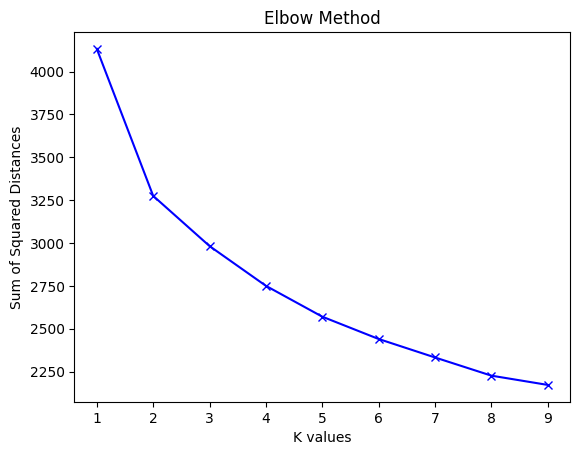

In [31]:
K = range(1,10)
sum_of_squared_distances = []

for k in K:
    model = KMeans(n_clusters=k, n_init=10).fit(transformed_data_2_scaled)
    sum_of_squared_distances.append(model.inertia_)

plt.plot(K, sum_of_squared_distances, 'bx-')
plt.xlabel('K values')
plt.ylabel('Sum of Squared Distances')
plt.title('Elbow Method')
plt.show()

In [32]:
kmeans = KMeans(n_clusters=2, n_init=10)
kmeans.fit(transformed_data_2_scaled)

labels = kmeans.predict(transformed_data_2_scaled)

centroids = kmeans.cluster_centers_
s = metrics.silhouette_score(transformed_data_2_scaled, labels, metric='euclidean')
print(f'Silhouette Coefficient for the data Dataset Clusters: {s:.2f}')

Silhouette Coefficient for the data Dataset Clusters: 0.20


In [33]:
plot_df = pd.DataFrame(transformed_data_2_scaled, columns=feature_names)
plot_df["Cluster"] = labels.astype(str)

fig = px.scatter_3d(plot_df, x="Income", y="NumDealsPurchases", z="Customer_Days",
                    color="Cluster", opacity=0.6)
fig.update_traces(marker=dict(size=3))
fig.show()

На візуалізації 2 кластери проглядаються, але межа між кластерами достаньо розмита.

**Завдання 9.** Використовуючи методи `scipy` `dendrogram, linkage, fcluster`
1. Побудуйте ієрархічну агломеративну кластеризацію з `single linkage` на даних невідмасштабованих, але з прибраним викидом.
2. Візуалізуйте дендрограму. При візуалізації обовʼязково задайте параметр `truncate_mode='lastp'` - це обріже дендрограму, без цього вона буде завелика, бо у нас тут даних суттєво більше, ніж в лекції.
3. Проаналізуйте дендрограму та побудуйте варіанти плоских кластеризацій з `fcluster` на 2 і 3 кластери. Візуалізуйте результати кожної з цих кластеризацій та зробіть висновок. Чи вважаєте ви якусь з цих кластеризацій вдалою? Що спостерігаєте з цих кластеризацій?
4. Порахуйте мерику силуету для цього методу кластеризації.

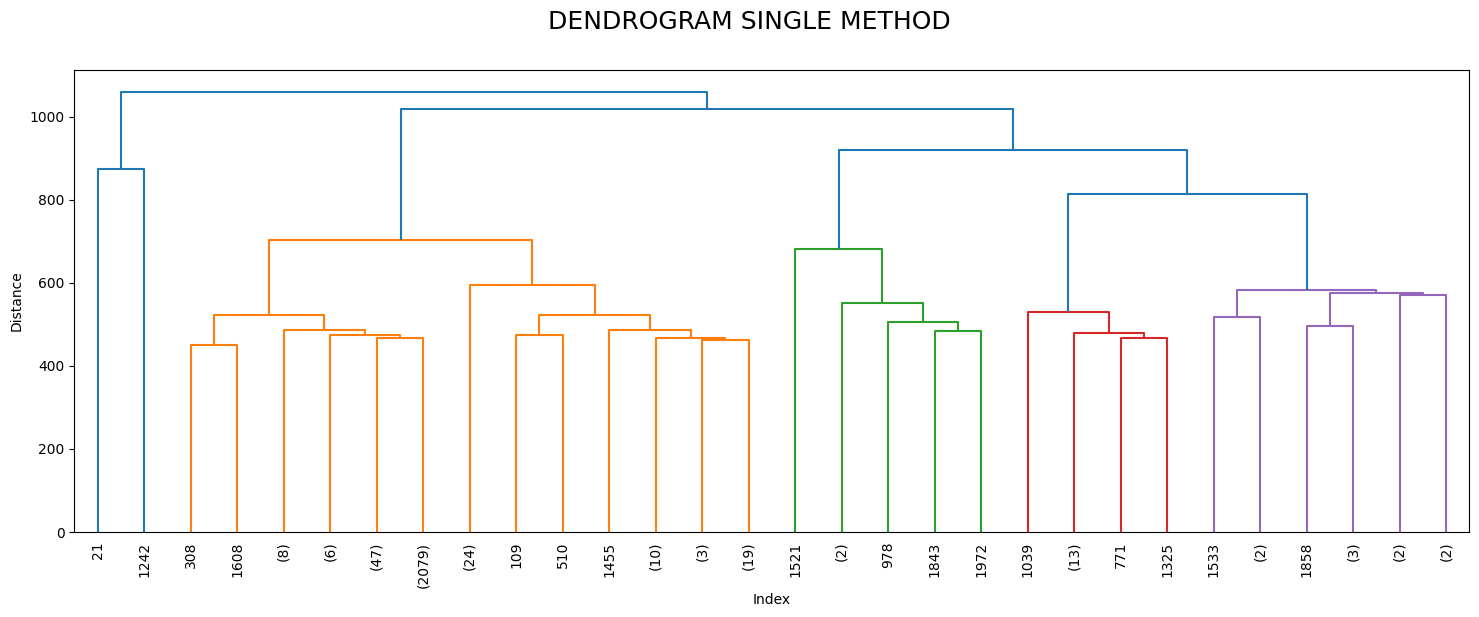

In [34]:
dist_sin = linkage(transformed_data_2, method="single")
plt.figure(figsize=(18,6))
dendrogram(dist_sin, leaf_rotation=90, truncate_mode="lastp")
plt.xlabel('Index')
plt.ylabel('Distance')
plt.suptitle("DENDROGRAM SINGLE METHOD",fontsize=18)
plt.show()

In [35]:
transformed_data_2['2_clust'] = fcluster(dist_sin, 2, criterion='maxclust')
transformed_data_2['3_clust'] = fcluster(dist_sin, 3, criterion='maxclust')

<Axes: title={'center': 'K = 3'}, xlabel='Income', ylabel='NumDealsPurchases'>

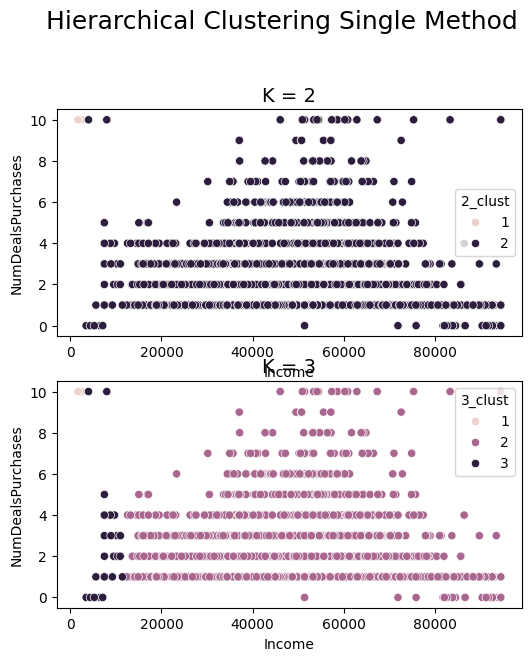

In [36]:
plt.figure(figsize=(6,10))

plt.suptitle("Hierarchical Clustering Single Method",fontsize=18)

plt.subplot(3,1,1)
plt.title("K = 2",fontsize=14)
sns.scatterplot(x="Income",y="NumDealsPurchases", data=transformed_data_2, hue="2_clust")

plt.subplot(3,1,2)
plt.title("K = 3",fontsize=14)
sns.scatterplot(x="Income",y="NumDealsPurchases", data=transformed_data_2, hue="3_clust")

Вважаю, що обидва варіанти невдалі.

2 кластери: майже всі дані потрапили в один кластер.

3 кластери: така ж сама історія, тільки додався третий кластер, який взяв до себе невелику частину даних з другого класу, але немає сенсу в такому розподіленні.

In [37]:
X = transformed_data_2.drop(columns=["2_clust", "3_clust"])

s2 = metrics.silhouette_score(X, transformed_data_2["2_clust"])
s3 = metrics.silhouette_score(X, transformed_data_2["3_clust"])

print(f"Silhouette Coefficient (2 clusters): {s2:.3f}")
print(f"Silhouette Coefficient (3 clusters): {s3:.3f}")

Silhouette Coefficient (2 clusters): 0.426
Silhouette Coefficient (3 clusters): 0.373


**Завдання 10.**
1. Використайте метод кластеризації, який ми не використовували в попередніх завданнях цього ДЗ (може бути ієрархічна кластеризація з іншим способом звʼязності або інші методи sklearn).
2. Порахуйте метрику силуету і візуалізуйте результат кластеризації. Зробіть висновок про те, чи могла б ця кластеризація бути корисною?

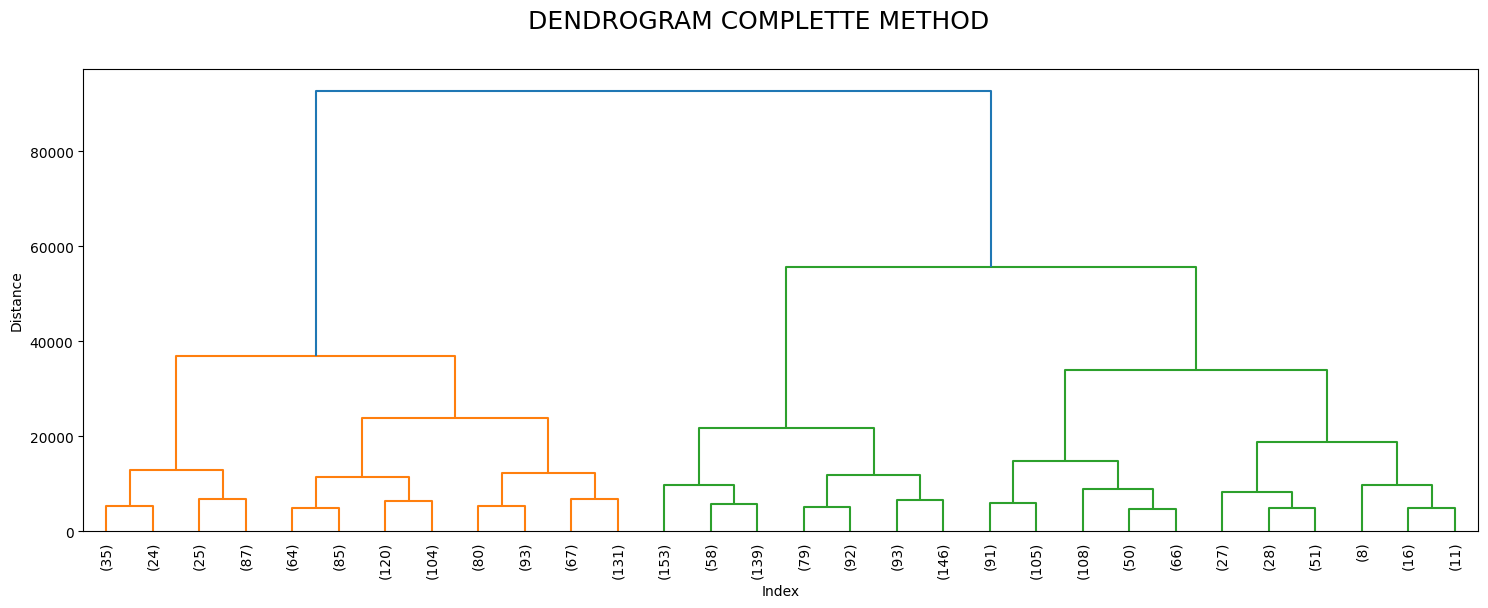

In [38]:
dist_sin = linkage(transformed_data_2, method="complete")
plt.figure(figsize=(18,6))
dendrogram(dist_sin, leaf_rotation=90, truncate_mode="lastp")
plt.xlabel('Index')
plt.ylabel('Distance')
plt.suptitle("DENDROGRAM COMPLETTE METHOD",fontsize=18)
plt.show()

In [39]:
transformed_data_2['2_clust'] = fcluster(dist_sin, 2, criterion='maxclust')
transformed_data_2['3_clust'] = fcluster(dist_sin, 3, criterion='maxclust')

X = transformed_data_2.drop(columns=["2_clust", "3_clust"])

s2 = metrics.silhouette_score(X, transformed_data_2["2_clust"])
s3 = metrics.silhouette_score(X, transformed_data_2["3_clust"])

print(f"Silhouette Coefficient (2 clusters): {s2:.3f}")
print(f"Silhouette Coefficient (3 clusters): {s3:.3f}")

Silhouette Coefficient (2 clusters): 0.592
Silhouette Coefficient (3 clusters): 0.544


<Axes: title={'center': 'K = 3'}, xlabel='Income', ylabel='NumDealsPurchases'>

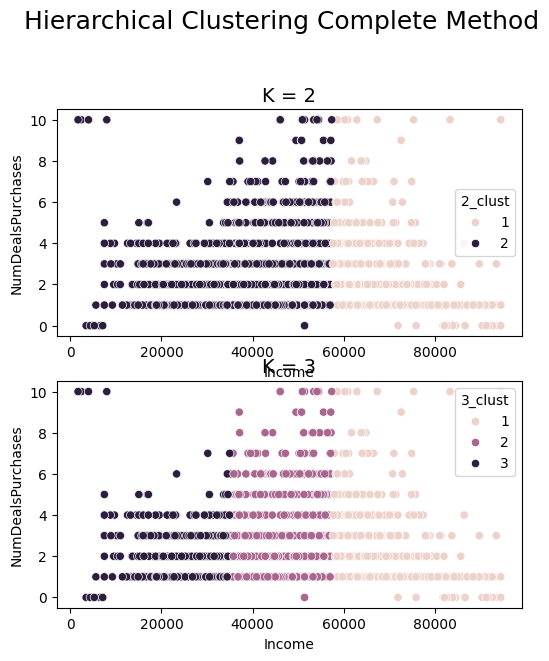

In [40]:
plt.figure(figsize=(6,10))

plt.suptitle("Hierarchical Clustering Complete Method",fontsize=18)

plt.subplot(3,1,1)
plt.title("K = 2",fontsize=14)
sns.scatterplot(x="Income",y="NumDealsPurchases", data=transformed_data_2, hue="2_clust")

plt.subplot(3,1,2)
plt.title("K = 3",fontsize=14)
sns.scatterplot(x="Income",y="NumDealsPurchases", data=transformed_data_2, hue="3_clust")

При використанні complete linkage методу результати вийшли краще ніж з single linkage. Коефіцієнт силуета вищий і для 2, і для 3 кластерів. На візуалізації також бачимо достатньо логічне розподілення, яке може бути корисне.

Якщо обирати між 2 і 3 кластерами, то тут потрібно мати більше інформації про продукцію обраної компанії і провести більше аналізу.